# 03 - Exploratory Data Analysis

## Objective

Here we explore the data further. We want to find out:

1. Why does the number of transactions drop around step 400?
2. Do fraud and non-fraud look different on features we know **before** a transaction (`oldbalanceOrg`, `amount`, `type`, `step`)?
3. Does the type of the destination account (customer or merchant) have a link with fraud?
4. Are these features correlated with fraud?
5. What is going on with the 16 fraud transactions where `amount == 0`?

We do not use `newbalanceOrig` and `newbalanceDest` here, because they look like a leakage risk. We measure this later in a separate notebook, with a model.

## Imports and Data Loading

In [40]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

DATA_PATH = os.path.join('..', 'data', 'raw', 'PS_20174392719_1491204439457_log.csv')

dtypes = {
    'step': 'int32',
    'type': 'category',
    'amount': 'float64',
    'nameOrig': 'string',
    'oldbalanceOrg': 'float64',
    'newbalanceOrig': 'float64',
    'nameDest': 'string',
    'oldbalanceDest': 'float64',
    'newbalanceDest': 'float64',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

df = pd.read_csv(DATA_PATH, dtype=dtypes)
df['amount_log'] = np.log1p(df['amount'])
print(f'Loaded {len(df):,} rows')

Loaded 6,362,620 rows


## 1. The Step Change

The volume of transactions drops around step 400. We split the data in two periods at this point and check if the mix of transaction types changes. For example, `PAYMENT` and `CASH_IN` could stop after step 400 while `CASH_OUT` and `TRANSFER` continue. We also compare the fraud rate in each period.

In [41]:
# Split into two periods at step 400 (the break seen in the time plot)
df['period'] = np.where(df['step'] <= 400, 'early (step<=400)', 'late (step>400)')

period_type = pd.crosstab(df['period'], df['type'], normalize='index') * 100
period_type.round(2)

type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
period,,,,,
early (step<=400),21.97,35.39,0.64,33.68,8.32
late (step>400),22.22,32.91,0.75,35.18,8.94


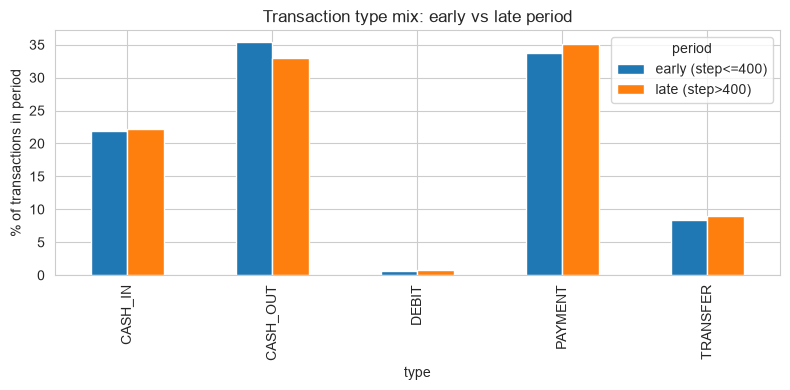

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
period_type.T.plot(kind='bar', ax=ax)
ax.set_ylabel('% of transactions in period')
ax.set_title('Transaction type mix: early vs late period')
plt.tight_layout()
plt.savefig('../reports/figures/type_mix_by_period.png', dpi=120)
plt.show()

In [43]:
# Fraud rate in each period
df.groupby('period')['isFraud'].agg(['size', 'sum', 'mean'])

,size,sum,mean
period,,,
early (step<=400),5787030,4477,0.000774
late (step>400),575590,3736,0.006491


**Type mix:** it barely changes between the two periods (`CASH_OUT` 35.4% vs 32.9%, `PAYMENT` 33.7% vs 35.2%). So it does not explain the drop in volume. We don't know the cause, so we treat it as a feature of the simulation.

**Fraud rate:** 0.077% in the early period vs 0.649% in the late period, about 8.4 times higher. But the number of frauds per step is the same in both periods (about 11), while the volume drops about 10 times. So the rate goes up only because there are fewer normal transactions.

This matters for the validation. If we train on the early period and test on the late one, the fraud rate will be very different on each side.

## 2. Origin Balance Before the Transaction

We use `oldbalanceOrg`, the balance before the transaction. We can know it before scoring a transaction, unlike `newbalanceOrig`.

In [44]:
df.groupby('isFraud')['oldbalanceOrg'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,8.328287e+05,2.887144e+06,0.0,0.00,14069.00,106969.50,43818855.30
1,8213.0,1.649668e+06,3.547719e+06,0.0,125822.44,438983.45,1517771.48,59585040.37


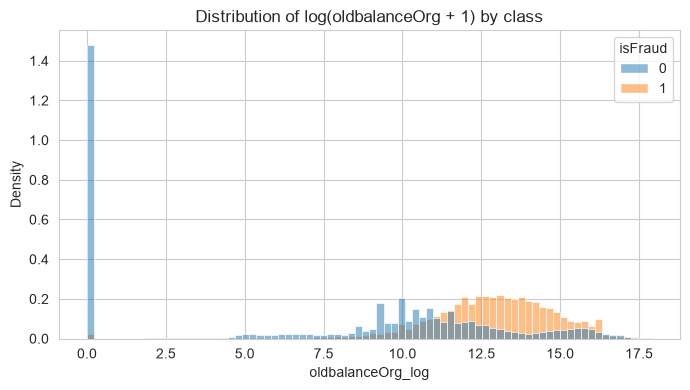

In [45]:
df['oldbalanceOrg_log'] = np.log1p(df['oldbalanceOrg'])

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x='oldbalanceOrg_log', hue='isFraud', bins=80, stat='density',
             common_norm=False, ax=ax)
ax.set_title('Distribution of log(oldbalanceOrg + 1) by class')
plt.tight_layout()
plt.savefig('../reports/figures/oldbalance_log_distribution.png', dpi=120)
plt.show()

In [46]:
# How often is the origin account already empty BEFORE the transaction?
# This is available at decision time, unlike the 'after' balance.
zero_old_balance = df['oldbalanceOrg'] == 0
df.groupby('isFraud').apply(lambda g: zero_old_balance.loc[g.index].mean()).round(4)

isFraud
0    0.3309
1    0.0050
dtype: float64

33.1% of non-fraud transactions start from an account with a zero balance, against only 0.5% of fraud. This makes sense: fraud goes after accounts that have money.

The histogram shows the same thing. Fraud is shifted to the right (median 438,983 vs 14,069 for non-fraud, about 31 times higher), but the two classes still overlap a lot. So it is a useful signal, but not a strong one alone. It is also very different from `newbalanceOrig`, which separated the classes almost completely, and it only uses information available before the transaction.

## 3. Amount Compared to the Origin Balance

A transaction that empties the account could be a signal. We compute `amount / oldbalanceOrg` (only when the balance is above 0). This also only uses information available before the transaction.

In [47]:
# Ratio of amount to available balance, only defined when oldbalanceOrg > 0.
has_balance = df['oldbalanceOrg'] > 0
df['amount_to_balance_ratio'] = np.where(has_balance, df['amount'] / df['oldbalanceOrg'], np.nan)

df.loc[has_balance].groupby('isFraud')['amount_to_balance_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,4251999.0,122.272735,4153.259060,1.765481e-08,0.07426,0.734717,6.684667,3.925476e+06
1,8172.0,0.998765,0.385326,3.837324e-02,1.00000,1.000000,1.000000,2.952662e+01


In [48]:
# Share of transactions that use ~100% or more of the available balance.
empties_account = df['amount_to_balance_ratio'] >= 0.99
df.loc[has_balance].groupby('isFraud').apply(lambda g: empties_account.loc[g.index].mean()).round(4)

isFraud
0    0.4660
1    0.9816
dtype: float64

Fraud almost always takes the whole balance. The median ratio is 1.0, and among rows with a balance, 98.2% of fraud uses at least 99% of it. For non-fraud it is 46.6%, and the ratios are much more spread out.

This is the strongest signal so far, and it only needs `amount` and `oldbalanceOrg`. But nearly half of non-fraud does the same, so it is not enough alone. Also, this ratio mixes all 5 types, and `CASH_IN` is a deposit, so it probably makes non-fraud look more spread out. We should check it by type later.

## 4. Destination Account Type

In [49]:
df['dest_type'] = np.where(df['nameDest'].str.startswith('M'), 'merchant', 'customer')
pd.crosstab(df['dest_type'], df['isFraud'])

isFraud,0,1
dest_type,,
customer,4202912,8213
merchant,2151495,0


In [50]:
pd.crosstab(df['dest_type'], df['isFraud'], normalize='index').round(6) * 100

isFraud,0,1
dest_type,,
customer,99.805,0.195
merchant,100.000,0.000


There is no fraud at all on merchant accounts (0 out of 2,151,495). Fraud only goes to customer accounts, where the rate is 0.195%. This is expected, because fraud only happens in `CASH_OUT` and `TRANSFER`, and these never go to merchants. So it adds nothing new.

## 5. Correlation Between Features

We only use `step`, `amount_log`, `oldbalanceOrg_log` and `isFraud`. We leave out `newbalanceOrig` and `newbalanceDest`.

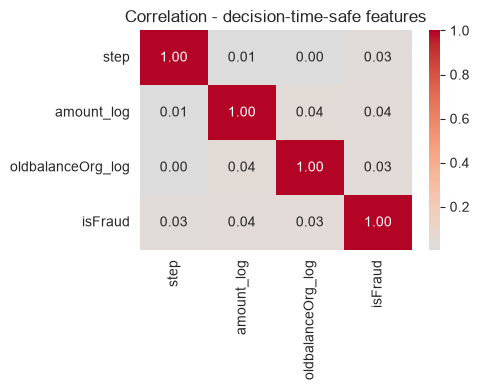

In [51]:
safe_cols = ['step', 'amount_log', 'oldbalanceOrg_log', 'isFraud']
corr = df[safe_cols].corr()

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation - decision-time-safe features')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_safe_features.png', dpi=120)
plt.show()

All correlations with `isFraud` are weak (0.03 to 0.04), even for features that show a clear gap above. Fraud seems to depend on a mix of things (amount compared to balance, for some types) more than on one variable in a straight line. A tree-based model should handle this better than a linear one, unless we create the ratio as a feature.

## 6. Zero-Amount Fraud Transactions

In [52]:
zero_amount_fraud = df[(df['amount'] == 0) & (df['isFraud'] == 1)]
zero_amount_fraud[['step', 'type', 'oldbalanceOrg', 'newbalanceOrig',
                    'oldbalanceDest', 'newbalanceDest']]

,step,type,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
2736447,212,CASH_OUT,0.0,0.0,0.00,0.00
3247298,250,CASH_OUT,0.0,0.0,0.00,0.00
3760289,279,CASH_OUT,0.0,0.0,538547.63,538547.63
5563714,387,CASH_OUT,0.0,0.0,7970766.57,7970766.57
5996408,425,CASH_OUT,0.0,0.0,76759.90,76759.90
5996410,425,CASH_OUT,0.0,0.0,2921531.34,2921531.34
6168500,554,CASH_OUT,0.0,0.0,230289.66,230289.66
6205440,586,CASH_OUT,0.0,0.0,1328472.86,1328472.86
6266414,617,CASH_OUT,0.0,0.0,0.00,0.00
6281483,646,CASH_OUT,0.0,0.0,0.00,0.00


In all 16 rows, the origin balance is 0 before and after, and the destination balance does not change. This looks like an edge case of how PaySim creates fraud, not a real fraud pattern. There are too few of them (0.19% of fraud cases) to matter, so we do nothing.

## 7. Summary

- **Step ~400**: the type mix is the same before and after, so it does not explain the drop in volume. The cause is unknown.
- **Fraud rate**: 8.4 times higher after step 400, but only because normal volume drops. Frauds per step stay about the same (~11). We must be careful with a time-based split.
- **`oldbalanceOrg`**: fraud has higher balances (median 31 times higher) and almost never starts from zero (0.5% vs 33.1%). Useful, but the classes overlap.
- **Amount-to-balance ratio**: 98.2% of fraud empties the account vs 46.6% of non-fraud. This is the strongest signal so far.
- **Correlations**: all weak (0.04 at most).
- **Merchants**: no fraud at all.
- **Zero-amount fraud**: an edge case of the simulation, ignored.

## 8. Next Steps

With only `type`, `amount`, `oldbalanceOrg` and the amount-to-balance ratio, we already see clear differences between fraud and non-fraud. So a good model may be possible without `newbalanceOrig` and `newbalanceDest`.

Next notebook: a leakage analysis. We train one model with these two columns and one without, on the same validation split, to see how much they inflate the results.